<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b> 🌊 Modelos ARFIMA: memoria larga en el río Nilo </b></h1>

---

**Seminario de Series de Tiempo I** · Universidad de Antioquia · 2026-2
Juan Camilo Melo Ortíz · Santiago Duque Pérez

Este notebook contiene el análisis reproducible de la sección de **Aplicación** del seminario *Más allá de ARMA y ARIMA: modelos ARFIMA para series con memoria larga*.

Usamos la serie de los **niveles mínimos anuales del río Nilo entre los años 622 y 1284**, medidos en el nilómetro de Roda, cerca de El Cairo. Es la serie clásica de la memoria larga: estudiando el Nilo fue que Hurst (1951) descubrió que los años secos tienden a venir seguidos de más años secos durante períodos mucho más largos de lo que un modelo de memoria corta puede explicar.

La idea es poner a competir tres modelos sobre la misma serie:

| Modelo | Qué supone |
|---|---|
| **ARMA$(p,q)$** | Memoria corta: la ACF cae exponencialmente ($d = 0$) |
| **ARIMA$(p,1,q)$** | Raíz unitaria: los choques son permanentes ($d = 1$) |
| **ARFIMA$(p,d,q)$** | Memoria larga: $d$ fraccionario, en la mitad de los dos |

Las figuras se muestran aquí y además se guardan en la carpeta `../figuras`, para usarlas en el documento de Overleaf.
</div>

## 📦 Paquetes

Solo se instalan los que falten.

In [1]:
paquetes <- c("fracdiff", "forecast", "tseries", "longmemo")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan, repos = "https://cloud.r-project.org")

suppressPackageStartupMessages({
  library(fracdiff)   # ARFIMA por máxima verosimilitud (Haslett y Raftery) y estimador GPH
  library(forecast)   # modelos ARMA, ARIMA y pronósticos
  library(tseries)    # pruebas ADF y KPSS
  library(longmemo)   # datos NileMin
})

# Carpeta donde se guardan las figuras para Overleaf
dir_fig <- "../figuras"
dir.create(dir_fig, showWarnings = FALSE)

# Grafica en el notebook y guarda la misma figura en PNG
graficar <- function(archivo, dibujo, ancho = 1600, alto = 800) {
  dibujo()
  png(file.path(dir_fig, archivo), width = ancho, height = alto, res = 150)
  dibujo()
  invisible(dev.off())
}

options(repr.plot.width = 14, repr.plot.height = 6)
set.seed(2026)

## 📊 1. Datos

El objeto `NileMin` viene indexado desde 1, así que le ponemos los años reales.

In [2]:
data(NileMin)
nilo <- ts(as.numeric(NileMin), start = 622)
n <- length(nilo)
paste("Número de observaciones:", n)
summary(nilo)

[1] "Número de observaciones: 663"

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    935    1094    1148    1148    1205    1466 

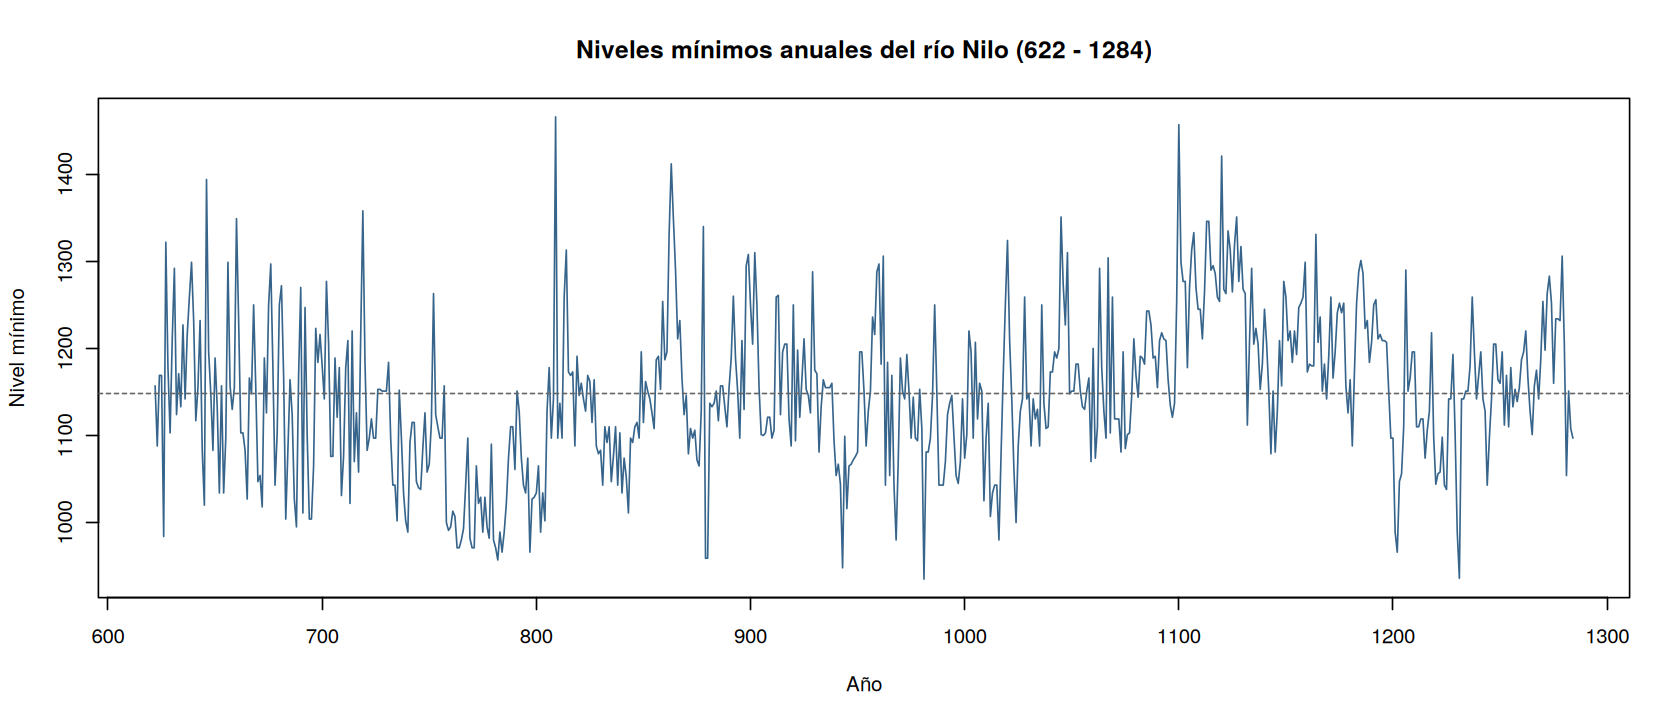

In [3]:
graficar("serie_nilo.png", function() {
  plot(nilo, xlab = "Año", ylab = "Nivel mínimo", col = "steelblue4",
       main = "Niveles mínimos anuales del río Nilo (622 - 1284)")
  abline(h = mean(nilo), lty = 2, col = "grey40")
}, alto = 700)

La serie no muestra tendencia ni estacionalidad, pero sí **rachas largas** por encima y por debajo de la media (por ejemplo, alrededor de los años 750 a 800 y 1100 a 1150). Ese es el efecto Hurst a simple vista.

## 🔍 2. Exploración: ACF y PACF muestrales

En un ARMA la ACF cae a cero de forma exponencial, en pocos rezagos. Si hay memoria larga, la ACF no tiene valores muy grandes pero **baja muy despacio**.

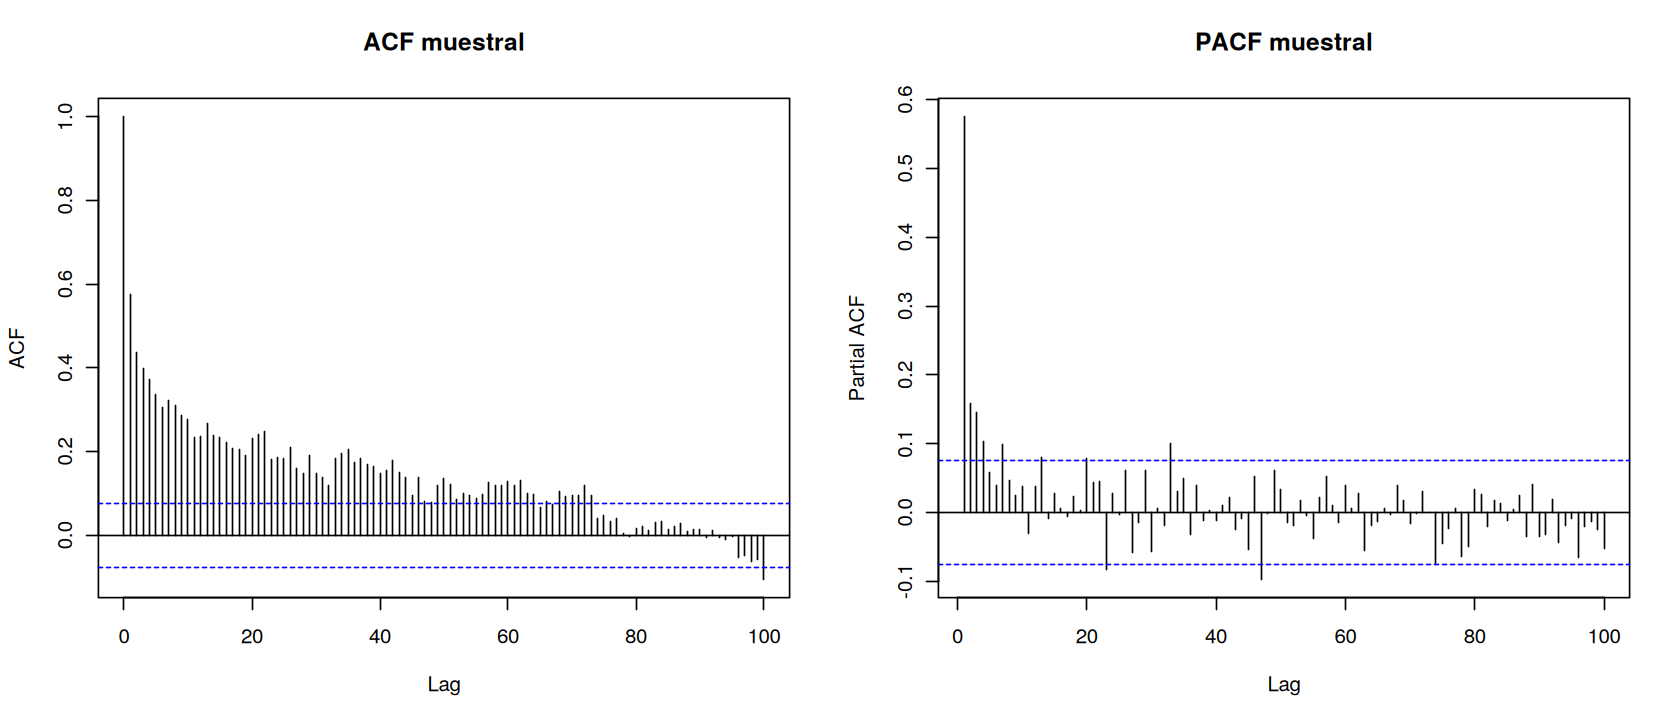

In [4]:
graficar("acf_pacf_nilo.png", function() {
  par(mfrow = c(1, 2))
  acf(nilo, lag.max = 100, main = "ACF muestral")
  pacf(nilo, lag.max = 100, main = "PACF muestral")
  par(mfrow = c(1, 1))
}, alto = 700)

In [5]:
r <- acf(nilo, lag.max = 100, plot = FALSE)$acf[-1]
data.frame(rezago = c(1, 5, 10, 20, 50, 100),
           acf = round(r[c(1, 5, 10, 20, 50, 100)], 3))
paste("Banda de significancia aproximada: +/-", round(1.96 / sqrt(n), 3))

rezago,acf
<dbl>,<dbl>
1,0.575
5,0.336
10,0.278
20,0.232
50,0.135
100,-0.105


[1] "Banda de significancia aproximada: +/- 0.076"

## 🧪 3. Pruebas de estacionariedad: ADF y KPSS

- **ADF** (Dickey-Fuller aumentada): $H_0$: hay raíz unitaria.
- **KPSS**: $H_0$: la serie es estacionaria.

Si la ADF rechaza la raíz unitaria **y** la KPSS rechaza la estacionariedad, la serie no se comporta ni como ARMA ni como ARIMA: es un indicio clásico de memoria larga.

In [6]:
adf.test(nilo)
kpss.test(nilo, null = "Level")

Warning message in adf.test(nilo):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  nilo
Dickey-Fuller = -5.0255, Lag order = 8, p-value = 0.01
alternative hypothesis: stationary


Warning message in kpss.test(nilo, null = "Level"):
“p-value smaller than printed p-value”



	KPSS Test for Level Stationarity

data:  nilo
KPSS Level = 1.7208, Truncation lag parameter = 6, p-value = 0.01


## 📐 4. Estimación del parámetro de memoria $d$

### 4a. Estimador GPH (Geweke y Porter-Hudak, 1983)

Regresión del log-periodograma sobre $\log[4\sin^2(\lambda_j/2)]$ usando solo las $m = n^{\alpha}$ frecuencias más bajas. La propuesta original es $\alpha = 0.5$; probamos también 0.6 y 0.7 para ver qué tan sensible es a $m$.

In [7]:
gph <- do.call(rbind, lapply(c(0.5, 0.6, 0.7), function(b) {
  g <- fdGPH(nilo, bandw.exp = b)
  data.frame(alpha = b, m = floor(n^b), d = g$d, EE_asint = g$sd.as)
}))
round(gph, 4)

alpha,m,d,EE_asint
<dbl>,<dbl>,<dbl>,<dbl>
0.5,25,0.5038,0.1570
0.6,49,0.5367,0.1045
0.7,94,0.3962,0.0725


### 4b. Máxima verosimilitud (Haslett y Raftery, 1989)

Ajustamos ARFIMA$(p,d,q)$ con $p, q \in \{0,1,2\}$ y los ordenamos por BIC.

In [8]:
tabla_arfima <- NULL
for (p in 0:2) for (q in 0:2) {
  f <- suppressWarnings(fracdiff(nilo, nar = p, nma = q))
  tabla_arfima <- rbind(tabla_arfima,
    data.frame(p = p, q = q, d = f$d, logLik = f$log.likelihood,
               AIC = AIC(f), BIC = BIC(f)))
}
tabla_arfima <- tabla_arfima[order(tabla_arfima$BIC), ]
rownames(tabla_arfima) <- NULL
round(tabla_arfima, 3)

p,q,d,logLik,AIC,BIC
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,0,0.393,-3757.762,7519.523,7528.517
0,1,0.353,-3758.062,7522.125,7535.615
1,0,0.355,-3758.157,7522.314,7535.804
2,2,0.384,-3750.999,7513.998,7540.979
1,1,0.365,-3757.794,7523.588,7541.575
2,0,0.385,-3757.823,7523.646,7541.633
0,2,0.380,-3757.836,7523.672,7541.659
2,1,0.380,-3757.765,7525.531,7548.015
1,2,0.378,-3757.820,7525.640,7548.124


In [9]:
# Modelo escogido: ARFIMA(0,d,0), el de menor BIC
fit_arfima <- fracdiff(nilo, nar = 0, nma = 0)
d_hat <- fit_arfima$d
se_d  <- sqrt(6 / (pi^2 * n))   # error estándar asintótico de d en un ARFIMA(0,d,0)

data.frame(d = round(d_hat, 4), EE = round(se_d, 4),
           IC95_inf = round(d_hat - 1.96 * se_d, 3),
           IC95_sup = round(d_hat + 1.96 * se_d, 3),
           Hurst = round(d_hat + 0.5, 3))

d,EE,IC95_inf,IC95_sup,Hurst
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.3933,0.0303,0.334,0.453,0.893


> **Nota:** el error estándar que imprime `summary(fit_arfima)` depende de un parámetro numérico interno de `fracdiff` (`h`) y no es confiable. Por eso usamos el error asintótico $\sqrt{6/(\pi^2 n)}$.

## ⚖️ 5. Modelos de comparación: ARMA ($d=0$) y ARIMA ($d=1$)

Escogemos el mejor de cada familia con `auto.arima`, sin búsqueda escalonada.

In [10]:
fit_arma  <- auto.arima(nilo, d = 0, stepwise = FALSE, approximation = FALSE)
fit_arima <- auto.arima(nilo, d = 1, stepwise = FALSE, approximation = FALSE)
fit_arma
fit_arima

Series: nilo 
ARIMA(2,0,1) with non-zero mean 

Coefficients:
         ar1      ar2      ma1       mean
      1.2762  -0.3002  -0.8532  1148.3979
s.e.  0.0713   0.0609   0.0535    16.0789

sigma^2 = 4908:  log likelihood = -3756.37
AIC=7522.74   AICc=7522.83   BIC=7545.23

Series: nilo 
ARIMA(1,1,3) 

Coefficients:
         ar1      ma1     ma2     ma3
      0.8089  -1.3816  0.2799  0.1199
s.e.  0.1215   0.1307  0.0887  0.0625

sigma^2 = 4937:  log likelihood = -3752.93
AIC=7515.86   AICc=7515.95   BIC=7538.33

In [11]:
ord_arma  <- arimaorder(fit_arma)
ord_arima <- arimaorder(fit_arima)
nombres <- c("ARFIMA(0,d,0)",
             sprintf("ARMA(%d,%d)", ord_arma[1], ord_arma[3]),
             sprintf("ARIMA(%d,1,%d)", ord_arima[1], ord_arima[3]))

comparacion <- data.frame(
  Modelo     = nombres,
  Parametros = c(1, ord_arma[1] + ord_arma[3], ord_arima[1] + ord_arima[3]),
  logLik     = c(fit_arfima$log.likelihood, fit_arma$loglik, fit_arima$loglik),
  AIC        = c(AIC(fit_arfima), fit_arma$aic, fit_arima$aic),
  BIC        = c(BIC(fit_arfima), fit_arma$bic, fit_arima$bic))
comparacion

Modelo,Parametros,logLik,AIC,BIC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
"ARFIMA(0,d,0)",1,-3757.762,7519.523,7528.517
"ARMA(2,1)",3,-3756.371,7522.743,7545.227
"ARIMA(1,1,3)",4,-3752.928,7515.856,7538.333


> **Ojo:** el AIC y el BIC del ARIMA con $d = 1$ se calculan sobre la serie **diferenciada**, así que no son comparables con los otros dos. La comparación justa entre los tres es la de pronóstico (sección 7).

### Periodograma vs. densidad espectral de cada modelo

En escala log-log, el espectro de un ARFIMA$(0,d,0)$ es casi una **recta con pendiente $-2d$** cerca del origen (se dispara en la frecuencia cero). El de un ARMA, en cambio, es acotado y tiene que aplanarse en la frecuencia cero.

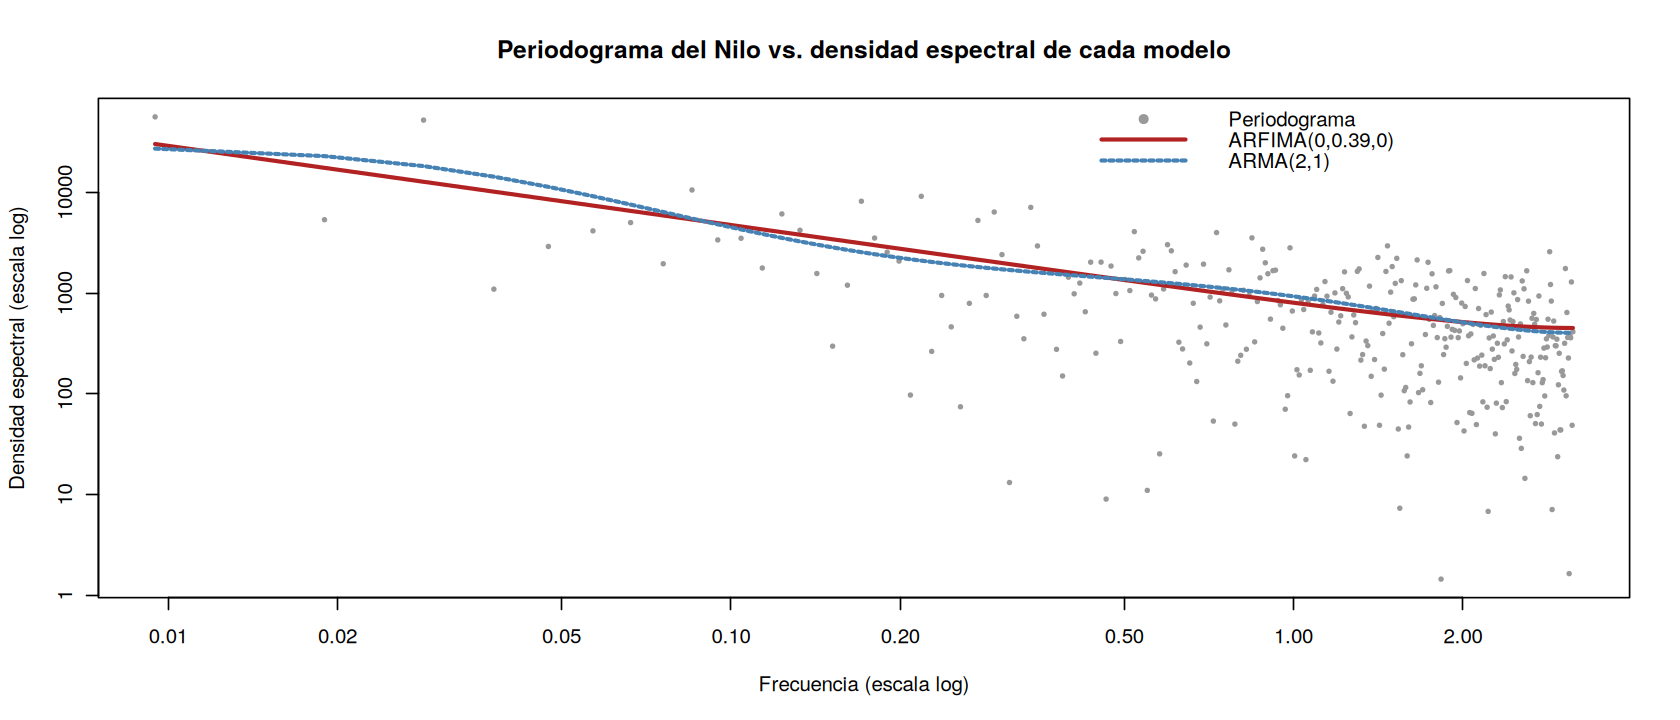

In [12]:
xc     <- as.numeric(nilo) - mean(nilo)
m_f    <- floor((n - 1) / 2)
lam    <- 2 * pi * (1:m_f) / n                              # frecuencias de Fourier
I_lam  <- (Mod(fft(xc))^2 / (2 * pi * n))[2:(m_f + 1)]      # periodograma

f_arfima <- fit_arfima$sigma^2 / (2 * pi) * (2 * sin(lam / 2))^(-2 * d_hat)

co   <- coef(fit_arma)
ar_c <- co[grep("^ar", names(co))]
ma_c <- co[grep("^ma", names(co))]
z    <- exp(-1i * lam)
phi_z   <- 1 - Reduce(`+`, lapply(seq_along(ar_c), function(k) ar_c[k] * z^k), 0)
theta_z <- 1 + Reduce(`+`, lapply(seq_along(ma_c), function(k) ma_c[k] * z^k), 0)
f_arma  <- fit_arma$sigma2 / (2 * pi) * Mod(theta_z)^2 / Mod(phi_z)^2

graficar("espectro_modelos.png", function() {
  plot(lam, I_lam, log = "xy", pch = 16, cex = 0.5, col = "grey60",
       xlab = "Frecuencia (escala log)", ylab = "Densidad espectral (escala log)",
       main = "Periodograma del Nilo vs. densidad espectral de cada modelo")
  lines(lam, f_arfima, col = "firebrick", lwd = 2.5)
  lines(lam, f_arma,   col = "steelblue", lwd = 2.5, lty = 2)
  legend("topright", bty = "n", pch = c(16, NA, NA), lty = c(NA, 1, 2),
         lwd = c(NA, 2.5, 2.5), col = c("grey60", "firebrick", "steelblue"),
         legend = c("Periodograma", sprintf("ARFIMA(0,%.2f,0)", d_hat), nombres[2]))
})

## 🩺 6. Diagnóstico de residuales

Prueba de Ljung-Box con 20 rezagos: $H_0$: los residuales son ruido blanco.

In [13]:
lb <- function(res, fitdf) Box.test(res, lag = 20, type = "Ljung-Box", fitdf = fitdf)$p.value
data.frame(Modelo = nombres,
           p_valor_LjungBox = round(c(lb(residuals(fit_arfima), 1),
                                      lb(residuals(fit_arma),  ord_arma[1] + ord_arma[3]),
                                      lb(residuals(fit_arima), ord_arima[1] + ord_arima[3])), 4))

Modelo,p_valor_LjungBox
<chr>,<dbl>
"ARFIMA(0,d,0)",0.8660
"ARMA(2,1)",0.8379
"ARIMA(1,1,3)",0.8343


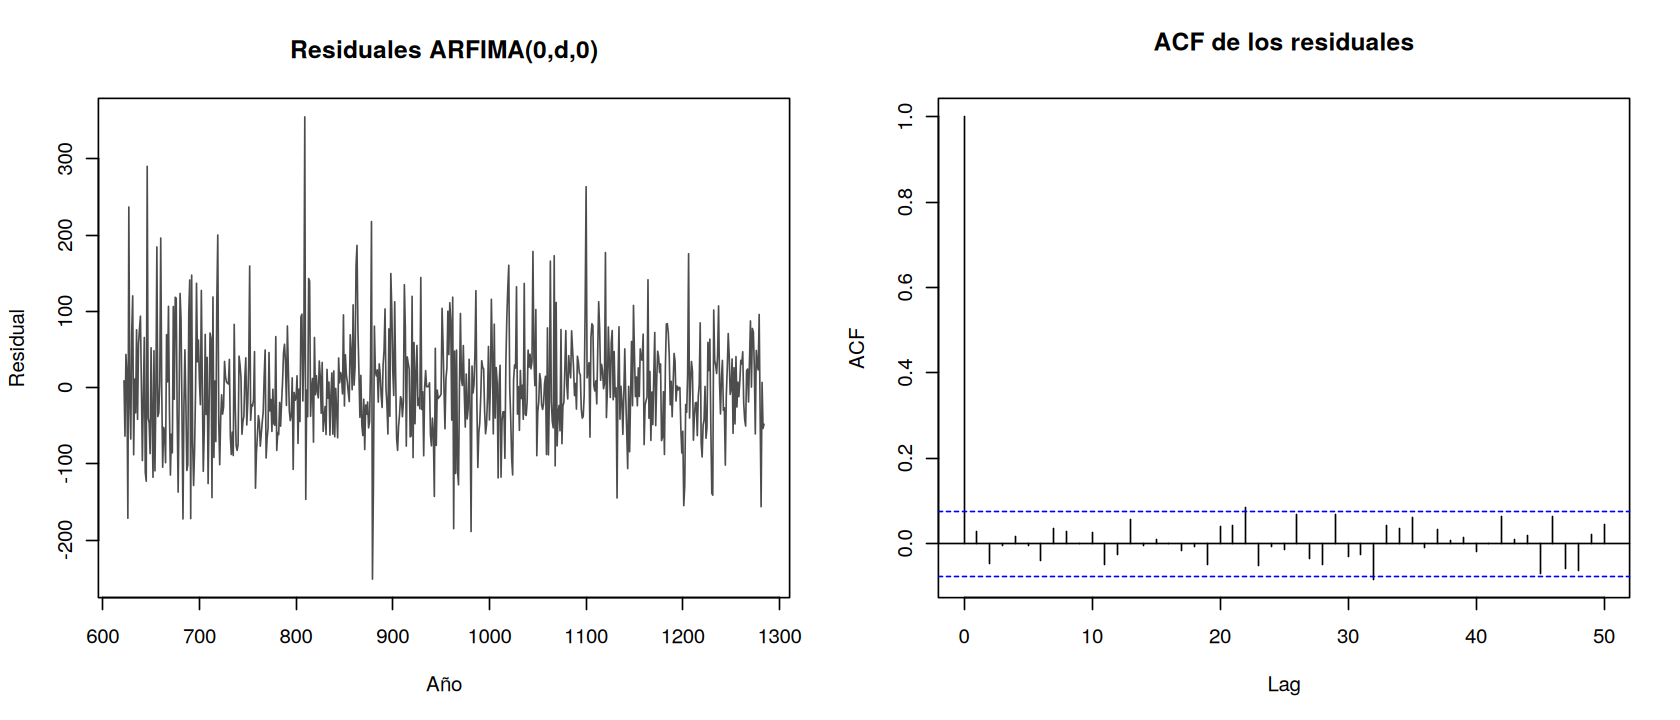

In [14]:
graficar("residuales_arfima.png", function() {
  par(mfrow = c(1, 2))
  plot(ts(residuals(fit_arfima), start = 622), ylab = "Residual", xlab = "Año",
       main = "Residuales ARFIMA(0,d,0)", col = "grey30")
  acf(residuals(fit_arfima), lag.max = 50, main = "ACF de los residuales")
  par(mfrow = c(1, 1))
}, alto = 700)

## 🔮 7. Pronóstico fuera de muestra

Separamos las **últimas 50 observaciones** (años 1235 a 1284) como prueba y estimamos los tres modelos solo con el entrenamiento. Usamos como referencia el pronóstico más ingenuo posible: la media del entrenamiento.

### 7a. Pronóstico a varios pasos (50 años hacia adelante)

In [15]:
h_test <- 50
train <- window(nilo, end = 1284 - h_test)
test  <- window(nilo, start = 1284 - h_test + 1)

tr_arfima <- fracdiff(train, nar = 0, nma = 0)
tr_arma   <- Arima(train, order = c(ord_arma[1], 0, ord_arma[3]), include.mean = TRUE)
tr_arima  <- Arima(train, order = c(ord_arima[1], 1, ord_arima[3]))

fc_arfima <- forecast(tr_arfima, h = h_test)
fc_arma   <- forecast(tr_arma,   h = h_test)
fc_arima  <- forecast(tr_arima,  h = h_test)

err <- function(pred) {
  e <- as.numeric(test) - as.numeric(pred)
  c(RMSE = sqrt(mean(e^2)), MAE = mean(abs(e)))
}
tabla_pron <- data.frame(
  Modelo = c(nombres, "Media (referencia)"),
  rbind(err(fc_arfima$mean), err(fc_arma$mean), err(fc_arima$mean),
        err(rep(mean(train), h_test))))
tabla_pron

Modelo,RMSE,MAE
<chr>,<dbl>,<dbl>
"ARFIMA(0,d,0)",62.59050,49.30301
"ARMA(2,1)",68.90066,55.98530
"ARIMA(1,1,3)",74.76852,60.76716
Media (referencia),60.73087,46.94421


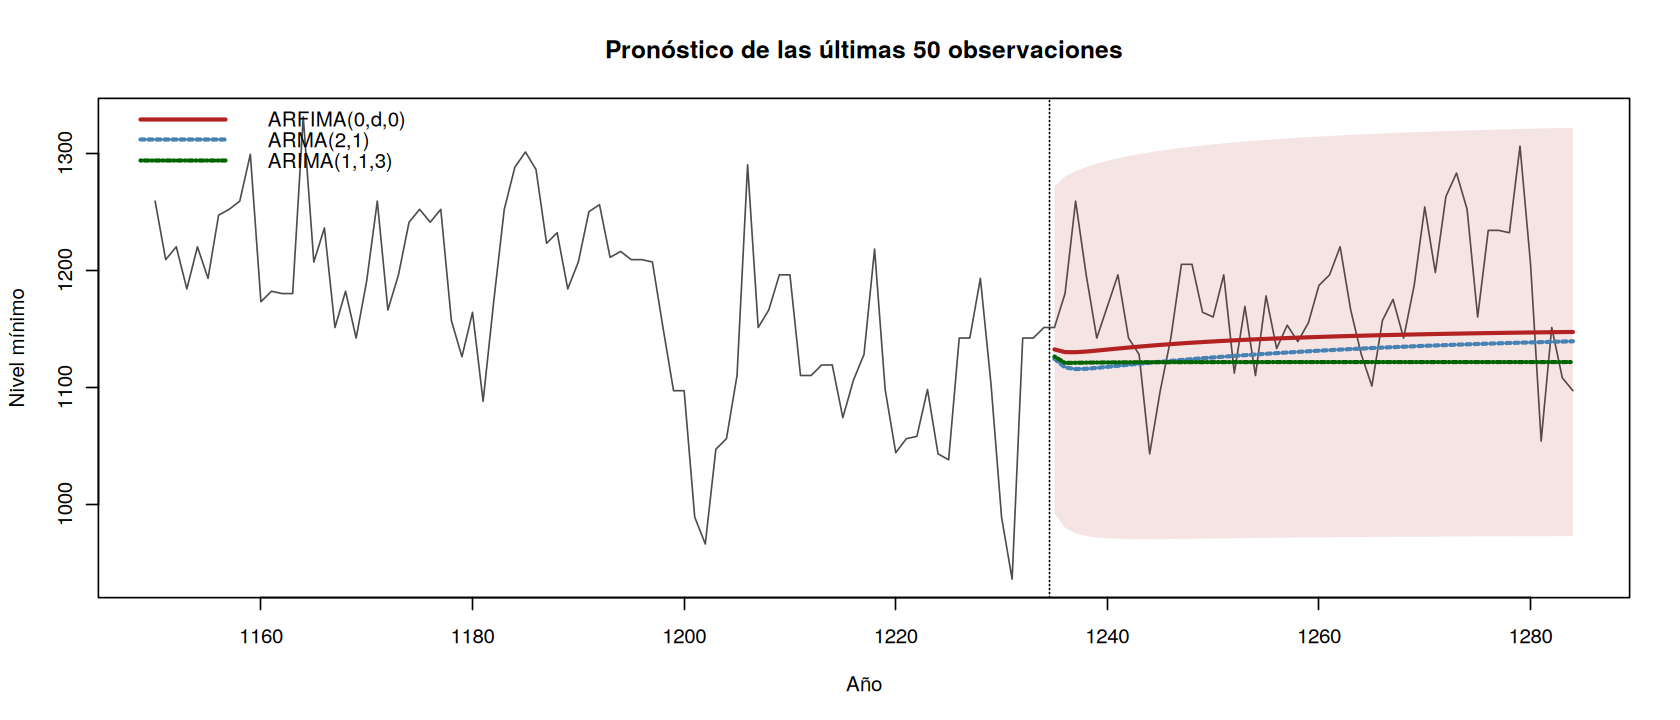

In [16]:
graficar("pronosticos.png", function() {
  ventana <- window(nilo, start = 1150)
  plot(ventana, xlim = c(1150, 1284),
       ylim = range(c(ventana, fc_arfima$lower[, 2], fc_arfima$upper[, 2])),
       xlab = "Año", ylab = "Nivel mínimo", col = "grey30",
       main = "Pronóstico de las últimas 50 observaciones")
  abline(v = 1284 - h_test + 0.5, lty = 3)
  polygon(c(time(test), rev(time(test))),
          c(fc_arfima$lower[, 2], rev(fc_arfima$upper[, 2])),
          col = adjustcolor("firebrick", 0.12), border = NA)
  lines(fc_arfima$mean, col = "firebrick", lwd = 2.5)
  lines(fc_arma$mean,   col = "steelblue", lwd = 2.5, lty = 2)
  lines(fc_arima$mean,  col = "darkgreen", lwd = 2.5, lty = 4)
  legend("topleft", bty = "n", lwd = 2.5, lty = c(1, 2, 4),
         col = c("firebrick", "steelblue", "darkgreen"), legend = nombres)
})

### 7b. Pronóstico a un paso

Los parámetros quedan fijos (estimados con el entrenamiento) y cada año se pronostica con toda la información hasta el año anterior.

Para el ARFIMA$(0,d,0)$ usamos su representación AR$(\infty)$: $\;x_t - \mu = -\sum_{j\ge1} \pi_j (x_{t-j}-\mu) + w_t$, con los pesos de $(1-B)^d$ calculados por la recursión $\pi_j = \pi_{j-1}\,(j-1-d)/j$.

In [17]:
idx <- (n - h_test + 1):n
d_tr <- tr_arfima$d
mu   <- mean(train)

pi_w <- numeric(n); pi_w[1] <- 1                # pi_w[j + 1] guarda pi_j
for (j in 1:(n - 1)) pi_w[j + 1] <- pi_w[j] * (j - 1 - d_tr) / j
xc_tr <- as.numeric(nilo) - mu
p1_arfima <- sapply(idx, function(t) mu - sum(pi_w[2:t] * xc_tr[(t - 1):1]))

# ARMA y ARIMA: se aplican los modelos de entrenamiento, sin reestimar, a toda la serie
p1_arma  <- fitted(Arima(nilo, model = tr_arma))[idx]
p1_arima <- fitted(Arima(nilo, model = tr_arima))[idx]

tabla_pron1 <- data.frame(
  Modelo = c(nombres, "Media (referencia)"),
  rbind(err(p1_arfima), err(p1_arma), err(p1_arima), err(rep(mu, h_test))))
tabla_pron1

Modelo,RMSE,MAE
<chr>,<dbl>,<dbl>
"ARFIMA(0,d,0)",50.10372,39.84892
"ARMA(2,1)",50.79394,40.70641
"ARIMA(1,1,3)",50.71067,40.53653
Media (referencia),60.73087,46.94421


---
<h1 align="center"><b> 🎬 ¡FIN! </b></h1>

---